# **PRCP-1001 RiceLeaf Disease Detection**

## **1. Problem Statement**

PRCP-1001 RiceLeaf Disease Detection

Goal:
Build an image classification model to detect rice leaf diseases:
1. Leaf smut
2. Brown spot
3. Bacterial leaf blight

Tasks:
- Data Analysis
- Data Augmentation
- Model Building
- Model Comparison
- Challenges & Conclusion

## **2. Import Libraries**

In [1]:
!pip install tensorflow

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
print("TensorFlow version:", tf.__version__)
import warnings
warnings.filterwarnings('ignore')

TensorFlow version: 2.20.0


## **3. Load Dataset**

In [3]:
data_path = "RiceLeaf Dataset"   # folder containing class folders

classes = os.listdir(data_path)
print("Classes:", classes)

Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


## **4. Exploratory Data Analysis (EDA)**

### Count Images per Class

In [4]:
for cls in classes:
    count = len(os.listdir(os.path.join(data_path, cls)))
    print(f"{cls}: {count} images")

Bacterial leaf blight: 41 images
Brown spot: 40 images
Leaf smut: 39 images


### Display Sample Images

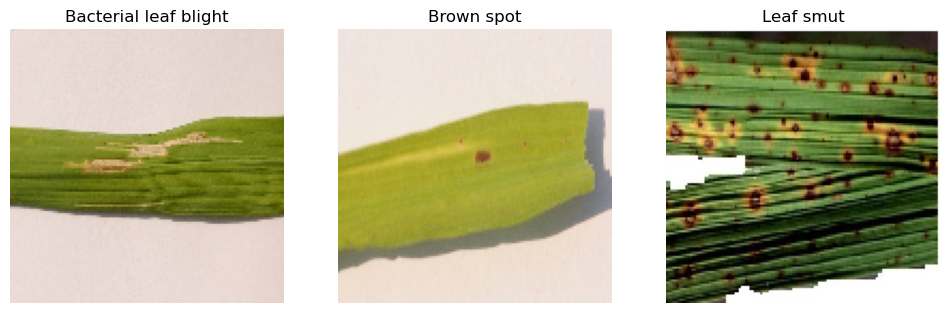

In [5]:
import random
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

plt.figure(figsize=(12,6))

for i, cls in enumerate(classes):

    folder = os.path.join(data_path, cls)

    images = [f for f in os.listdir(folder)
              if f.lower().endswith(('.png','.jpg','.jpeg'))]

    img_name = random.choice(images)
    img_path = os.path.join(folder, img_name)

    img = image.load_img(img_path, target_size=(128,128))

    plt.subplot(1,3,i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.show()

## **5. Data Preprocessing & Augmentation**

### Since dataset is small (120 images), augmentation is necessary.

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

train_generator = train_datagen.flow_from_directory(
    data_path,
    target_size=(128,128),
    batch_size=16,
    class_mode='categorical',
    subset='training'
)

val_generator = train_datagen.flow_from_directory(
    data_path,
    target_size=(128,128),
    batch_size=16,
    class_mode='categorical',
    subset='validation'
)

Found 97 images belonging to 3 classes.
Found 23 images belonging to 3 classes.


## **6. Model 1 — Basic CNN**

In [7]:
cnn_model = Sequential()

cnn_model.add(Conv2D(32,(3,3),activation='relu',input_shape=(128,128,3)))
cnn_model.add(MaxPooling2D(2,2))

cnn_model.add(Conv2D(64,(3,3),activation='relu'))
cnn_model.add(MaxPooling2D(2,2))

cnn_model.add(Flatten())
cnn_model.add(Dense(128,activation='relu'))
cnn_model.add(Dropout(0.5))
cnn_model.add(Dense(3,activation='softmax'))

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       7,372,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,392,707 (28.20 MB)

 Trainable params: 7,392,707 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

## **7. Train Basic CNN**

In [8]:
history_cnn = cnn_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 930ms/step - accuracy: 0.2887 - loss: 2.3335 - val_accuracy: 0.3478 - val_loss: 1.2825
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 616ms/step - accuracy: 0.3814 - loss: 1.1126 - val_accuracy: 0.7391 - val_loss: 0.9826
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 721ms/step - accuracy: 0.4330 - loss: 1.0299 - val_accuracy: 0.3043 - val_loss: 1.1253
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 584ms/step - accuracy: 0.3608 - loss: 1.1342 - val_accuracy: 0.6087 - val_loss: 0.8149
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 595ms/step - accuracy: 0.5155 - loss: 0.9616 - val_accuracy: 0.5217 - val_loss: 0.8784
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 563ms/step - accuracy: 0.5361 - loss: 0.9582 - val_accuracy: 0.5217 - val_loss: 0.9331
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 583ms/step - accuracy: 0.5361 - loss: 0.9776 - val_accuracy: 0.6087 - val_loss: 0.7697
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 675ms/step - accuracy: 0.5567 - loss: 0.8552 - val_accuracy: 0.6522 - val_loss:

## **8. Evaluate CNN Model**

In [9]:
val_generator.reset()

pred = cnn_model.predict(val_generator)
pred_classes = np.argmax(pred, axis=1)

true_classes = val_generator.classes
class_labels = list(val_generator.class_indices.keys())

print(classification_report(true_classes, pred_classes, target_names=class_labels))

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 234ms/step
                       precision    recall  f1-score   support

Bacterial leaf blight       0.23      0.38      0.29         8
           Brown spot       0.20      0.25      0.22         8
            Leaf smut       0.00      0.00      0.00         7

             accuracy                           0.22        23
            macro avg       0.14      0.21      0.17        23
         weighted avg       0.15      0.22      0.18        23



## **9. Confusion Matrix**

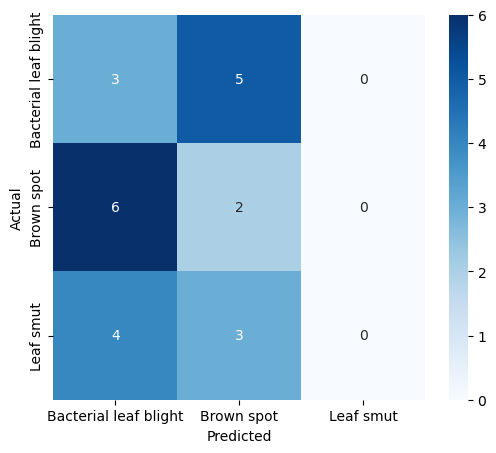

In [10]:
cm = confusion_matrix(true_classes, pred_classes)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## **10. Model 2 — Transfer Learning (Best Model)**

In [11]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128,128,3)
)

base_model.trainable = False   # freeze pretrained weights

### Build Transfer Learning Model

In [12]:
from tensorflow.keras.layers import GlobalAveragePooling2D

transfer_model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(3, activation='softmax')
])

transfer_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

transfer_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         163,968 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## **11. Train Transfer Learning Model**

In [13]:
history_transfer = transfer_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 11s 883ms/step - accuracy: 0.3814 - loss: 1.4126 - val_accuracy: 0.7391 - val_loss: 0.6439
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 497ms/step - accuracy: 0.7010 - loss: 0.8150 - val_accuracy: 0.9130 - val_loss: 0.4076
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 518ms/step - accuracy: 0.7835 - loss: 0.4908 - val_accuracy: 0.7391 - val_loss: 0.6122
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 592ms/step - accuracy: 0.8763 - loss: 0.3400 - val_accuracy: 0.8696 - val_loss: 0.4051
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 511ms/step - accuracy: 0.8351 - loss: 0.3635 - val_accuracy: 0.9130 - val_loss: 0.3592
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 602ms/step - accuracy: 0.8660 - loss: 0.2603 - val_accuracy: 0.7391 - val_loss: 0.6689
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 607ms/step - accuracy: 0.9278 - loss: 0.2408 - val_accuracy: 0.8261 - val_loss: 0.4728
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 660ms/step - accuracy: 0.8557 - loss: 0.3588 - val_accuracy: 0.8696 - val_loss

## **12. Evaluate Transfer Learning Model**

In [14]:
val_generator.reset()

pred2 = transfer_model.predict(val_generator)
pred_classes2 = np.argmax(pred2, axis=1)

print(classification_report(true_classes, pred_classes2, target_names=class_labels))

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step
                       precision    recall  f1-score   support

Bacterial leaf blight       0.62      0.62      0.62         8
           Brown spot       0.17      0.12      0.14         8
            Leaf smut       0.33      0.43      0.38         7

             accuracy                           0.39        23
            macro avg       0.38      0.39      0.38        23
         weighted avg       0.38      0.39      0.38        23



## **13. Plot Accuracy Comparison**

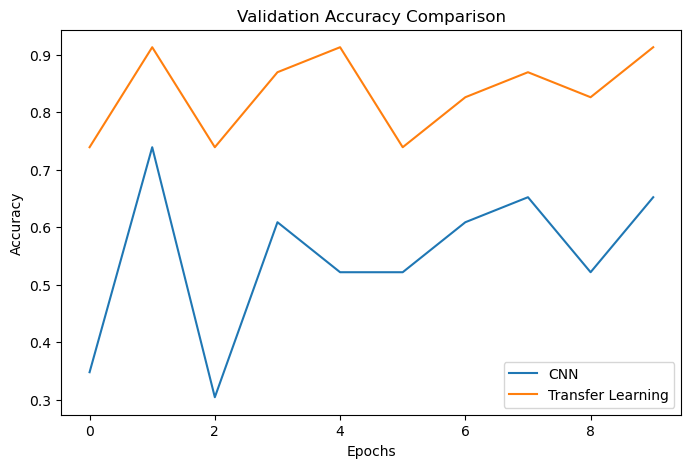

In [15]:
plt.figure(figsize=(8,5))

plt.plot(history_cnn.history['val_accuracy'], label='CNN')
plt.plot(history_transfer.history['val_accuracy'], label='Transfer Learning')

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

## **14. Model Comparison Report**

Model Comparison:

1. Basic CNN:
- Simple architecture
- Moderate accuracy
- Overfitting observed

2. Transfer Learning (MobileNetV2):
- Higher accuracy
- Faster convergence
- Better generalization

Best Model:
Transfer Learning model selected for production.

## **15. Challenges Faced**

Challenges:
1. Small dataset size → solved using data augmentation.
2. Overfitting → solved using dropout and transfer learning.
3. Similar disease patterns → deep features helped.
4. Image variations → normalization and augmentation used.

## **16. Final Conclusion**

Conclusion:
Transfer learning significantly improved performance compared to a basic CNN due to limited dataset size. Data augmentation helped improve robustness. The final model can classify rice leaf diseases effectively and can be extended for real-world agricultural applications.